# Optimized Method Evaluation

This notebook compares three anomaly detection approaches for the smart-building dataset:

- V3 statistical baseline, converted to budget-controlled labels for fair comparison.
- LOF sensitivity labels at 3%, 5%, and 9%.
- Optimized period-specific Isolation Forest labels at matching budgets.

The evaluation is split into two rankings:

1. **Quantitative proxy ranking**: budget adherence, persistence, cross-method consensus, and coverage. This avoids using V3 full baseline overlap as a scored criterion, because that would unfairly favor the V3 method itself.
2. **Practical selection ranking**: combines quantitative performance with interpretability, operational context, and output readiness.

There is no human-confirmed ground truth label in this project. The ranking is therefore a structured proxy evaluation, not an accuracy, precision, recall, or F1 evaluation.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Markdown


def locate_project_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "Artificial Intelligence for Smart-Building Log Analysis",
        *cwd.parents,
        *[parent / "Artificial Intelligence for Smart-Building Log Analysis" for parent in cwd.parents],
    ]
    for candidate in candidates:
        if (candidate / "outputs").exists() and (candidate / "ml").exists():
            return candidate
    raise FileNotFoundError("Cannot locate project directory")


PROJECT_DIR = locate_project_dir()
OUTPUT_DIR = PROJECT_DIR / "outputs" / "floor6_zone1245_model_method_evaluation_optimized"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BUDGETS = [0.03, 0.05, 0.09]
KEY_COLUMNS = ["timestamp", "floor", "zone"]
EVENT_MIN_DURATION_MINUTES = 30
EVENT_MAX_GAP_MINUTES = 2

BASELINE_SCORE_PATH = (
    PROJECT_DIR
    / "outputs/floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
    / "baseline_tables/09_baseline_anomaly_scores_long.csv.gz"
)
BASELINE_EVENTS_PATH = (
    PROJECT_DIR
    / "outputs/floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
    / "baseline_tables/11_baseline_anomaly_events.csv"
)
LOF_RESULTS_PATH = PROJECT_DIR / "outputs/floor6_zone1245_lof_modelling_gavin/lof_anomaly_results_full.csv.gz"
IF_RESULTS_PATH = PROJECT_DIR / "outputs/isolation_forest_huaye/if_period_auto_results_full.csv.gz"
IF_EVENTS_PATH = PROJECT_DIR / "outputs/isolation_forest_huaye/if_period_auto_events.csv"
IF_EVENT_SUMMARY_PATH = PROJECT_DIR / "outputs/isolation_forest_huaye/if_period_auto_event_summary.csv"

required_paths = [
    BASELINE_SCORE_PATH,
    BASELINE_EVENTS_PATH,
    LOF_RESULTS_PATH,
    IF_RESULTS_PATH,
    IF_EVENTS_PATH,
    IF_EVENT_SUMMARY_PATH,
]
missing = [str(path.relative_to(PROJECT_DIR)) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing required outputs: {missing}")

print(f"Project directory: {PROJECT_DIR}")
print(f"Evaluation output directory: {OUTPUT_DIR}")
print(f"Budgets: {[f'{budget:.0%}' for budget in BUDGETS]}")


Project directory: D:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis
Evaluation output directory: D:\IRP\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_model_method_evaluation_optimized
Budgets: ['3%', '5%', '9%']


In [2]:
if_header = pd.read_csv(IF_RESULTS_PATH, nrows=0).columns.tolist()
baseline_method_label_columns = [
    column
    for column in if_header
    if column.startswith("baseline_") and column.endswith("_label") and column != "baseline_anomaly_label"
]

if_usecols = list(dict.fromkeys(
    KEY_COLUMNS
    + [
        "hour",
        "operating_period",
        "baseline_anomaly_label",
        "baseline_anomaly_count",
        "baseline_anomaly_methods",
        "baseline_anomaly_variables",
        "baseline_anomaly_directions",
        "period_if_anomaly_label",
        "period_if_auto_anomaly_label",
        "period_if_anomaly_score",
        "period_if_threshold_score",
    ]
    + baseline_method_label_columns
))
aligned = pd.read_csv(IF_RESULTS_PATH, usecols=if_usecols, parse_dates=["timestamp"])
if aligned.duplicated(KEY_COLUMNS).any():
    raise AssertionError("IF-aligned table contains duplicate keys")

lof_usecols = KEY_COLUMNS + [
    "lof_score_k100",
    "lof_label_k100_c030",
    "lof_label_k100_c050",
    "lof_label_k100_c090",
]
lof = pd.read_csv(LOF_RESULTS_PATH, usecols=lof_usecols, parse_dates=["timestamp"])
aligned = aligned.merge(lof, on=KEY_COLUMNS, how="left", validate="one_to_one")
lof_label_columns = ["lof_label_k100_c030", "lof_label_k100_c050", "lof_label_k100_c090"]
if aligned[["lof_score_k100", *lof_label_columns]].isna().any().any():
    raise AssertionError("LOF sensitivity labels failed to align")

baseline_events_native = pd.read_csv(BASELINE_EVENTS_PATH, parse_dates=["start_time", "end_time"])
if_events_native = pd.read_csv(IF_EVENTS_PATH, parse_dates=["start_time", "end_time"])
if_event_summary = pd.read_csv(IF_EVENT_SUMMARY_PATH)

load_summary = pd.DataFrame([
    {
        "rows": len(aligned),
        "zones": aligned["zone"].nunique(),
        "operating_periods": aligned["operating_period"].nunique(),
        "start_time": aligned["timestamp"].min(),
        "end_time": aligned["timestamp"].max(),
        "v3_full_anomaly_count": int(aligned["baseline_anomaly_label"].sum()),
        "v3_full_anomaly_rate_pct": float(100 * aligned["baseline_anomaly_label"].mean()),
        "if_persistent_event_count": int(len(if_events_native)),
    }
])
display(load_summary.T.rename(columns={0: "value"}))
display(if_event_summary)


,value
rows,362880
zones,4
operating_periods,6
start_time,2018-07-01 00:00:00
end_time,2018-09-01 23:59:00
v3_full_anomaly_count,46659
v3_full_anomaly_rate_pct,12.85797
if_persistent_event_count,134


,operating_period,point_anomaly_count,point_anomaly_rate_pct,event_count,persistent_event_points,event_point_capture_pct,mean_duration_minutes,max_duration_minutes,mean_anomaly_points,max_anomaly_score,baseline_overlap_points,lof_overlap_points
0,night_off,3780,5.0,50,1884,49.841270,37.740000,65.0,37.680000,0.767036,127,199
1,ramp_up,540,5.0,0,0,0.000000,0.000000,0.0,0.000000,0.000000,0,0
2,core_work,4860,5.0,23,3739,76.934156,162.869565,540.0,162.565217,0.669088,3707,110
3,ramp_down,1080,5.0,12,819,75.833333,68.250000,120.0,68.250000,0.706011,423,69
4,evening_off,2700,5.0,25,1746,64.666667,70.000000,138.0,69.840000,0.699522,244,263
5,weekend,5184,5.0,24,4866,93.865741,202.916667,615.0,202.750000,0.803150,529,71


In [3]:
def _coerce_bool(values: pd.Series) -> pd.Series:
    if pd.api.types.is_bool_dtype(values):
        return values.astype(bool)
    if pd.api.types.is_numeric_dtype(values):
        return values.fillna(0).astype(int).astype(bool)
    return values.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])


def load_v3_row_scores(scores_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    usecols = KEY_COLUMNS + ["score_for_ranking", "is_anomaly"]
    partials = []
    for chunk in pd.read_csv(scores_path, usecols=usecols, parse_dates=["timestamp"], chunksize=chunksize):
        chunk["is_anomaly"] = _coerce_bool(chunk["is_anomaly"])
        chunk["score_for_ranking"] = pd.to_numeric(chunk["score_for_ranking"], errors="coerce").fillna(0)
        partials.append(
            chunk.groupby(KEY_COLUMNS, as_index=False).agg(
                v3_score_for_ranking=("score_for_ranking", "max"),
                v3_full_label_from_scores=("is_anomaly", "max"),
            )
        )
    row_scores = pd.concat(partials, ignore_index=True)
    row_scores = row_scores.groupby(KEY_COLUMNS, as_index=False).agg(
        v3_score_for_ranking=("v3_score_for_ranking", "max"),
        v3_full_label_from_scores=("v3_full_label_from_scores", "max"),
    )
    row_scores["v3_full_label_from_scores"] = row_scores["v3_full_label_from_scores"].astype("int8")
    return row_scores


v3_scores = load_v3_row_scores(BASELINE_SCORE_PATH)
aligned = aligned.merge(v3_scores, on=KEY_COLUMNS, how="left", validate="one_to_one")
if aligned[["v3_score_for_ranking", "v3_full_label_from_scores"]].isna().any().any():
    raise AssertionError("V3 scores failed to align")

agreement = float((aligned["baseline_anomaly_label"].astype(int) == aligned["v3_full_label_from_scores"].astype(int)).mean())
print(f"V3 full label agreement between score-long and aligned table: {agreement:.6f}")


V3 full label agreement between score-long and aligned table: 1.000000


In [4]:
def suffix_for_budget(budget: float) -> str:
    return f"{int(round(budget * 1000)):03d}"


def assign_top_budget_within_period(frame: pd.DataFrame, score_col: str, budget: float) -> pd.Series:
    labels = pd.Series(np.zeros(len(frame), dtype=np.int8), index=frame.index)
    for _, group in frame.groupby("operating_period", observed=True):
        count = max(1, int(np.ceil(len(group) * budget)))
        selected = group[score_col].sort_values(ascending=False).head(count).index
        labels.loc[selected] = 1
    return labels.astype("int8")


for budget in BUDGETS:
    suffix = suffix_for_budget(budget)
    lof_column = f"lof_label_k100_c{suffix}"
    if lof_column not in aligned.columns:
        raise KeyError(f"Missing LOF sensitivity column: {lof_column}")
    aligned[f"v3_budget_label_c{suffix}"] = assign_top_budget_within_period(aligned, "v3_score_for_ranking", budget)
    aligned[f"if_budget_label_c{suffix}"] = assign_top_budget_within_period(aligned, "period_if_anomaly_score", budget)
    aligned[f"lof_budget_label_c{suffix}"] = aligned[lof_column].astype("int8")

budget_check = []
for budget in BUDGETS:
    suffix = suffix_for_budget(budget)
    for method_key, label_col in [
        ("v3_budgeted", f"v3_budget_label_c{suffix}"),
        ("lof", f"lof_budget_label_c{suffix}"),
        ("optimized_if", f"if_budget_label_c{suffix}"),
    ]:
        budget_check.append(
            {
                "budget_pct": 100 * budget,
                "method_key": method_key,
                "label_col": label_col,
                "anomaly_count": int(aligned[label_col].sum()),
                "anomaly_rate_pct": float(100 * aligned[label_col].mean()),
            }
        )
budget_check = pd.DataFrame(budget_check)
display(budget_check)


,budget_pct,method_key,label_col,anomaly_count,anomaly_rate_pct
0,3.0,v3_budgeted,v3_budget_label_c030,10887,3.000165
1,3.0,lof,lof_budget_label_c030,10886,2.999890
2,3.0,optimized_if,if_budget_label_c030,10887,3.000165
3,5.0,v3_budgeted,v3_budget_label_c050,18144,5.000000
4,5.0,lof,lof_budget_label_c050,18144,5.000000
5,5.0,optimized_if,if_budget_label_c050,18144,5.000000
6,9.0,v3_budgeted,v3_budget_label_c090,32660,9.000220
7,9.0,lof,lof_budget_label_c090,32659,8.999945
8,9.0,optimized_if,if_budget_label_c090,32660,9.000220


In [5]:
METHOD_CONFIG = {
    "v3_budgeted": {
        "method_name": "V3 budgeted baseline",
        "method_family": "statistical_profile",
        "context_score": 1.00,
        "explainability_score": 1.00,
        "output_readiness_score": 0.95,
        "notes": "Interpretable V3 statistical baseline converted to the same anomaly budgets.",
    },
    "lof": {
        "method_name": "LOF",
        "method_family": "unsupervised_ml",
        "context_score": 0.55,
        "explainability_score": 0.50,
        "output_readiness_score": 0.65,
        "notes": "Native LOF labels at 3%, 5%, and 9% contamination.",
    },
    "optimized_if": {
        "method_name": "Optimized Isolation Forest",
        "method_family": "unsupervised_ml",
        "context_score": 0.90,
        "explainability_score": 0.75,
        "output_readiness_score": 0.90,
        "notes": "Period-specific IF score with budgeted thresholds and persistent-event outputs.",
    },
}

QUANTITATIVE_WEIGHTS = {
    "budget_adherence_score": 0.20,
    "persistence_score": 0.25,
    "consensus_score": 0.25,
    "period_coverage_score": 0.15,
    "zone_coverage_score": 0.15,
}

PRACTICAL_WEIGHTS = {
    "quantitative_proxy_score_normalized": 0.50,
    "context_score": 0.20,
    "explainability_score": 0.15,
    "output_readiness_score": 0.15,
}


def jaccard(left: pd.Series, right: pd.Series) -> tuple[int, int, float]:
    left_mask = left.astype(bool)
    right_mask = right.astype(bool)
    overlap = int((left_mask & right_mask).sum())
    union = int((left_mask | right_mask).sum())
    return overlap, union, float(overlap / union) if union else 0.0


def normalized_entropy(values: pd.Series, all_categories: list | None = None) -> float:
    if values.empty:
        return 0.0
    if all_categories is None:
        all_categories = sorted(values.dropna().unique().tolist())
    if len(all_categories) <= 1:
        return 1.0
    counts = values.value_counts().reindex(all_categories, fill_value=0).astype(float)
    probs = counts[counts.gt(0)] / counts.sum()
    entropy = float(-(probs * np.log(probs)).sum())
    return float(entropy / np.log(len(all_categories)))


def build_row_events(frame: pd.DataFrame, label_col: str, method_key: str, budget: float) -> pd.DataFrame:
    anomaly_rows = (
        frame.loc[frame[label_col].eq(1), ["timestamp", "zone", "operating_period", label_col]]
        .sort_values(["zone", "operating_period", "timestamp"])
        .copy()
    )
    columns = [
        "budget_pct",
        "method_key",
        "event_id",
        "zone",
        "operating_period",
        "start_time",
        "end_time",
        "anomaly_points",
        "duration_minutes",
    ]
    if anomaly_rows.empty:
        return pd.DataFrame(columns=columns)

    group_cols = ["zone", "operating_period"]
    gap_minutes = anomaly_rows.groupby(group_cols, observed=True)["timestamp"].diff().dt.total_seconds().div(60)
    new_event = gap_minutes.isna() | gap_minutes.gt(EVENT_MAX_GAP_MINUTES)
    anomaly_rows["_event_group"] = new_event.groupby(
        [anomaly_rows["zone"], anomaly_rows["operating_period"]], observed=True
    ).cumsum()
    events = (
        anomaly_rows.groupby(group_cols + ["_event_group"], observed=True)
        .agg(
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            anomaly_points=(label_col, "sum"),
        )
        .reset_index()
        .drop(columns="_event_group")
    )
    events["duration_minutes"] = ((events["end_time"] - events["start_time"]).dt.total_seconds().div(60).astype(int) + 1)
    events = events.loc[events["duration_minutes"].ge(EVENT_MIN_DURATION_MINUTES)].copy()
    events = events.sort_values(["duration_minutes", "anomaly_points"], ascending=[False, False]).reset_index(drop=True)
    events.insert(0, "event_id", np.arange(1, len(events) + 1, dtype=int))
    events.insert(0, "method_key", method_key)
    events.insert(0, "budget_pct", 100 * budget)
    return events[columns]


In [6]:
metric_rows = []
event_frames = []
overlap_rows = []
period_categories = sorted(aligned["operating_period"].dropna().unique().tolist())
zone_categories = sorted(aligned["zone"].dropna().unique().tolist())

for budget in BUDGETS:
    suffix = suffix_for_budget(budget)
    labels_by_method = {
        "v3_budgeted": f"v3_budget_label_c{suffix}",
        "lof": f"lof_budget_label_c{suffix}",
        "optimized_if": f"if_budget_label_c{suffix}",
    }

    for method_key, label_col in labels_by_method.items():
        labels = aligned[label_col].astype(int)
        config = METHOD_CONFIG[method_key]
        anomaly_count = int(labels.sum())
        events = build_row_events(aligned, label_col, method_key, budget)
        event_frames.append(events)
        v3_full_overlap, _, v3_full_jaccard = jaccard(labels, aligned["baseline_anomaly_label"])
        metric_rows.append(
            {
                "budget_pct": 100 * budget,
                "method_key": method_key,
                "method_name": config["method_name"],
                "method_family": config["method_family"],
                "label_col": label_col,
                "anomaly_count": anomaly_count,
                "anomaly_rate_pct": float(100 * labels.mean()),
                "target_budget_pct": 100 * budget,
                "budget_error_pct": abs(float(100 * labels.mean()) - 100 * budget),
                "v3_full_overlap_count_reference_only": v3_full_overlap,
                "v3_full_jaccard_reference_only": v3_full_jaccard,
                "common_event_count": int(len(events)),
                "common_event_anomaly_points": int(events["anomaly_points"].sum()) if not events.empty else 0,
                "persistent_point_share": float(events["anomaly_points"].sum() / anomaly_count) if anomaly_count else 0.0,
                "mean_common_event_duration": float(events["duration_minutes"].mean()) if not events.empty else 0.0,
                "max_common_event_duration": int(events["duration_minutes"].max()) if not events.empty else 0,
                "period_coverage_score": normalized_entropy(aligned.loc[labels.eq(1), "operating_period"], period_categories),
                "zone_coverage_score": normalized_entropy(aligned.loc[labels.eq(1), "zone"], zone_categories),
                "notes": config["notes"],
            }
        )

    method_items = list(labels_by_method.items())
    for i, (left_key, left_col) in enumerate(method_items):
        for right_key, right_col in method_items[i + 1 :]:
            overlap, union, overlap_jaccard = jaccard(aligned[left_col], aligned[right_col])
            overlap_rows.append(
                {
                    "budget_pct": 100 * budget,
                    "left_key": left_key,
                    "right_key": right_key,
                    "left_label_col": left_col,
                    "right_label_col": right_col,
                    "overlap_count": overlap,
                    "union_count": union,
                    "jaccard_overlap": overlap_jaccard,
                }
            )

metrics = pd.DataFrame(metric_rows)
events_all = pd.concat(event_frames, ignore_index=True) if event_frames else pd.DataFrame()
pairwise_overlap = pd.DataFrame(overlap_rows)

metrics.to_csv(OUTPUT_DIR / "01_budgeted_point_metrics.csv", index=False)
events_all.to_csv(OUTPUT_DIR / "02_budgeted_common_rule_events.csv", index=False)
pairwise_overlap.to_csv(OUTPUT_DIR / "03_pairwise_overlap_by_budget.csv", index=False)

display(metrics)
display(pairwise_overlap)


,budget_pct,method_key,method_name,method_family,label_col,anomaly_count,anomaly_rate_pct,target_budget_pct,budget_error_pct,v3_full_overlap_count_reference_only,v3_full_jaccard_reference_only,common_event_count,common_event_anomaly_points,persistent_point_share,mean_common_event_duration,max_common_event_duration,period_coverage_score,zone_coverage_score,notes
0,3.0,v3_budgeted,V3 budgeted baseline,statistical_profile,v3_budget_label_c030,10887,3.000165,3.0,0.000165,9682,0.202281,66,9043,0.830624,137.045455,817,0.889400,0.971299,Interpretable V3 statistical baseline converte...
1,3.0,lof,LOF,unsupervised_ml,lof_budget_label_c030,10886,2.999890,3.0,0.000110,1895,0.034052,73,5263,0.483465,72.178082,600,0.851484,0.985246,"Native LOF labels at 3%, 5%, and 9% contaminat..."
2,3.0,optimized_if,Optimized Isolation Forest,unsupervised_ml,if_budget_label_c030,10887,3.000165,3.0,0.000165,3866,0.072019,77,6750,0.620006,87.935065,610,0.889400,0.900078,Period-specific IF score with budgeted thresho...
3,5.0,v3_budgeted,V3 budgeted baseline,statistical_profile,v3_budget_label_c050,18144,5.000000,5.0,0.000000,13805,0.270697,118,14946,0.823743,126.686441,848,0.889410,0.988635,Interpretable V3 statistical baseline converte...
4,5.0,lof,LOF,unsupervised_ml,lof_budget_label_c050,18144,5.000000,5.0,0.000000,2874,0.046408,138,9676,0.533289,70.195652,600,0.855712,0.991245,"Native LOF labels at 3%, 5%, and 9% contaminat..."
5,5.0,optimized_if,Optimized Isolation Forest,unsupervised_ml,if_budget_label_c050,18144,5.000000,5.0,0.000000,6237,0.106495,134,13054,0.719466,97.552239,615,0.889410,0.929533,Period-specific IF score with budgeted thresho...
6,9.0,v3_budgeted,V3 budgeted baseline,statistical_profile,v3_budget_label_c090,32660,9.000220,9.0,0.000220,19145,0.318161,204,27398,0.838885,134.352941,957,0.889406,0.988629,Interpretable V3 statistical baseline converte...
7,9.0,lof,LOF,unsupervised_ml,lof_budget_label_c090,32659,8.999945,9.0,0.000055,5206,0.070245,225,17556,0.537555,78.066667,600,0.873429,0.995509,"Native LOF labels at 3%, 5%, and 9% contaminat..."
8,9.0,optimized_if,Optimized Isolation Forest,unsupervised_ml,if_budget_label_c090,32660,9.000220,9.0,0.000220,11318,0.166439,247,24832,0.760318,100.680162,749,0.889406,0.955193,Period-specific IF score with budgeted thresho...


,budget_pct,left_key,right_key,left_label_col,right_label_col,overlap_count,union_count,jaccard_overlap
0,3.0,v3_budgeted,lof,v3_budget_label_c030,lof_budget_label_c030,458,21315,0.021487
1,3.0,v3_budgeted,optimized_if,v3_budget_label_c030,if_budget_label_c030,1740,20034,0.086852
2,3.0,lof,optimized_if,lof_budget_label_c030,if_budget_label_c030,561,21212,0.026447
3,5.0,v3_budgeted,lof,v3_budget_label_c050,lof_budget_label_c050,1183,35105,0.033699
4,5.0,v3_budgeted,optimized_if,v3_budget_label_c050,if_budget_label_c050,3458,32830,0.105330
5,5.0,lof,optimized_if,lof_budget_label_c050,if_budget_label_c050,1253,35035,0.035764
6,9.0,v3_budgeted,lof,v3_budget_label_c090,lof_budget_label_c090,4855,60464,0.080296
7,9.0,v3_budgeted,optimized_if,v3_budget_label_c090,if_budget_label_c090,9193,56127,0.163789
8,9.0,lof,optimized_if,lof_budget_label_c090,if_budget_label_c090,3609,61710,0.058483


In [7]:
consensus_rows = []
for _, row in metrics[["budget_pct", "method_key"]].drop_duplicates().iterrows():
    relevant = pairwise_overlap.loc[
        pairwise_overlap["budget_pct"].eq(row["budget_pct"])
        & (pairwise_overlap["left_key"].eq(row["method_key"]) | pairwise_overlap["right_key"].eq(row["method_key"]))
    ]
    consensus_rows.append(
        {
            "budget_pct": row["budget_pct"],
            "method_key": row["method_key"],
            "mean_pairwise_jaccard": float(relevant["jaccard_overlap"].mean()) if not relevant.empty else 0.0,
            "max_pairwise_jaccard": float(relevant["jaccard_overlap"].max()) if not relevant.empty else 0.0,
        }
    )

scored = metrics.merge(pd.DataFrame(consensus_rows), on=["budget_pct", "method_key"], how="left")
ranked_frames = []
for budget_pct, group in scored.groupby("budget_pct", observed=True):
    group = group.copy()
    max_consensus = max(float(group["mean_pairwise_jaccard"].max()), 1e-9)
    group["budget_adherence_score"] = (1 - group["budget_error_pct"] / max(budget_pct, 1)).clip(lower=0, upper=1)
    group["persistence_score"] = group["persistent_point_share"].clip(lower=0, upper=1)
    group["consensus_score"] = (group["mean_pairwise_jaccard"] / max_consensus).clip(lower=0, upper=1)
    for score_col in ["context_score", "explainability_score", "output_readiness_score"]:
        group[score_col] = group["method_key"].map({key: config[score_col] for key, config in METHOD_CONFIG.items()})
    group["quantitative_proxy_score"] = sum(group[column] * weight for column, weight in QUANTITATIVE_WEIGHTS.items())
    max_quant = max(float(group["quantitative_proxy_score"].max()), 1e-9)
    group["quantitative_proxy_score_normalized"] = group["quantitative_proxy_score"] / max_quant
    group["practical_selection_score"] = sum(group[column] * weight for column, weight in PRACTICAL_WEIGHTS.items())

    quantitative = group.sort_values("quantitative_proxy_score", ascending=False).reset_index(drop=True)
    quantitative["quantitative_rank"] = np.arange(1, len(quantitative) + 1)
    practical = group.sort_values("practical_selection_score", ascending=False).reset_index(drop=True)
    practical["practical_rank"] = np.arange(1, len(practical) + 1)
    group = group.merge(
        quantitative[["method_key", "quantitative_rank"]], on="method_key", how="left"
    ).merge(
        practical[["method_key", "practical_rank"]], on="method_key", how="left"
    )
    ranked_frames.append(group)

ranking = pd.concat(ranked_frames, ignore_index=True)
quantitative_columns = [
    "budget_pct",
    "quantitative_rank",
    "method_name",
    "method_key",
    "method_family",
    "quantitative_proxy_score",
    "anomaly_rate_pct",
    "common_event_count",
    "persistent_point_share",
    "period_coverage_score",
    "zone_coverage_score",
    "mean_pairwise_jaccard",
    "v3_full_jaccard_reference_only",
    "budget_adherence_score",
    "persistence_score",
    "consensus_score",
    "notes",
]
practical_columns = [
    "budget_pct",
    "practical_rank",
    "method_name",
    "method_key",
    "method_family",
    "practical_selection_score",
    "quantitative_proxy_score",
    "context_score",
    "explainability_score",
    "output_readiness_score",
    "anomaly_rate_pct",
    "common_event_count",
    "persistent_point_share",
    "v3_full_jaccard_reference_only",
    "notes",
]

quantitative_ranking = ranking[quantitative_columns].sort_values(["budget_pct", "quantitative_rank"])
practical_ranking = ranking[practical_columns].sort_values(["budget_pct", "practical_rank"])

quantitative_ranking.to_csv(OUTPUT_DIR / "04_quantitative_proxy_ranking.csv", index=False)
practical_ranking.to_csv(OUTPUT_DIR / "05_practical_selection_ranking.csv", index=False)

stability = (
    ranking.groupby(["method_key", "method_name", "method_family"], observed=True)
    .agg(
        mean_quantitative_rank=("quantitative_rank", "mean"),
        best_quantitative_rank=("quantitative_rank", "min"),
        worst_quantitative_rank=("quantitative_rank", "max"),
        mean_quantitative_score=("quantitative_proxy_score", "mean"),
        quantitative_rank_1_count=("quantitative_rank", lambda values: int((values == 1).sum())),
        mean_practical_rank=("practical_rank", "mean"),
        best_practical_rank=("practical_rank", "min"),
        worst_practical_rank=("practical_rank", "max"),
        mean_practical_score=("practical_selection_score", "mean"),
        practical_rank_1_count=("practical_rank", lambda values: int((values == 1).sum())),
        budgets_tested=("budget_pct", "nunique"),
    )
    .reset_index()
    .sort_values(["mean_practical_rank", "mean_practical_score"], ascending=[True, False])
)
stability.to_csv(OUTPUT_DIR / "06_budget_stability_summary.csv", index=False)

display(Markdown("## Quantitative proxy ranking"))
display(quantitative_ranking)
display(Markdown("## Practical selection ranking"))
display(practical_ranking)
display(Markdown("## Budget stability summary"))
display(stability)


## Quantitative proxy ranking

,budget_pct,quantitative_rank,method_name,method_key,method_family,quantitative_proxy_score,anomaly_rate_pct,common_event_count,persistent_point_share,period_coverage_score,zone_coverage_score,mean_pairwise_jaccard,v3_full_jaccard_reference_only,budget_adherence_score,persistence_score,consensus_score,notes
0,3.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.925805,3.000165,66,0.830624,0.889400,0.971299,0.054170,0.202281,0.999945,0.830624,0.956222,Interpretable V3 statistical baseline converte...
2,3.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.873412,3.000165,77,0.620006,0.889400,0.900078,0.056650,0.072019,0.999945,0.620006,1.000000,Period-specific IF score with budgeted thresho...
1,3.0,3,LOF,lof,unsupervised_ml,0.702138,2.999890,73,0.483465,0.851484,0.985246,0.023967,0.034052,0.999963,0.483465,0.423077,"Native LOF labels at 3%, 5%, and 9% contaminat..."
3,5.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.933983,5.000000,118,0.823743,0.889410,0.988635,0.069515,0.270697,1.000000,0.823743,0.985362,Interpretable V3 statistical baseline converte...
5,5.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.902708,5.000000,134,0.719466,0.889410,0.929533,0.070547,0.106495,1.000000,0.719466,1.000000,Period-specific IF score with budgeted thresho...
4,5.0,3,LOF,lof,unsupervised_ml,0.733445,5.000000,138,0.533289,0.855712,0.991245,0.034732,0.046408,1.000000,0.533289,0.492316,"Native LOF labels at 3%, 5%, and 9% contaminat..."
6,9.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.941422,9.000220,204,0.838885,0.889406,0.988629,0.122042,0.318161,0.999976,0.838885,1.000000,Interpretable V3 statistical baseline converte...
8,9.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.894423,9.000220,247,0.760318,0.889406,0.955193,0.111136,0.166439,0.999976,0.760318,0.910636,Period-specific IF score with budgeted thresho...
7,9.0,3,LOF,lof,unsupervised_ml,0.756870,8.999945,225,0.537555,0.873429,0.995509,0.069389,0.070245,0.999994,0.537555,0.568568,"Native LOF labels at 3%, 5%, and 9% contaminat..."


## Practical selection ranking

,budget_pct,practical_rank,method_name,method_key,method_family,practical_selection_score,quantitative_proxy_score,context_score,explainability_score,output_readiness_score,anomaly_rate_pct,common_event_count,persistent_point_share,v3_full_jaccard_reference_only,notes
0,3.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.992500,0.925805,1.00,1.00,0.95,3.000165,66,0.830624,0.202281,Interpretable V3 statistical baseline converte...
2,3.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.899204,0.873412,0.90,0.75,0.90,3.000165,77,0.620006,0.072019,Period-specific IF score with budgeted thresho...
1,3.0,3,LOF,lof,unsupervised_ml,0.661704,0.702138,0.55,0.50,0.65,2.999890,73,0.483465,0.034052,"Native LOF labels at 3%, 5%, and 9% contaminat..."
3,5.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.992500,0.933983,1.00,1.00,0.95,5.000000,118,0.823743,0.270697,Interpretable V3 statistical baseline converte...
5,5.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.910757,0.902708,0.90,0.75,0.90,5.000000,134,0.719466,0.106495,Period-specific IF score with budgeted thresho...
4,5.0,3,LOF,lof,unsupervised_ml,0.675144,0.733445,0.55,0.50,0.65,5.000000,138,0.533289,0.046408,"Native LOF labels at 3%, 5%, and 9% contaminat..."
6,9.0,1,V3 budgeted baseline,v3_budgeted,statistical_profile,0.992500,0.941422,1.00,1.00,0.95,9.000220,204,0.838885,0.318161,Interpretable V3 statistical baseline converte...
8,9.0,2,Optimized Isolation Forest,optimized_if,unsupervised_ml,0.902539,0.894423,0.90,0.75,0.90,9.000220,247,0.760318,0.166439,Period-specific IF score with budgeted thresho...
7,9.0,3,LOF,lof,unsupervised_ml,0.684483,0.756870,0.55,0.50,0.65,8.999945,225,0.537555,0.070245,"Native LOF labels at 3%, 5%, and 9% contaminat..."


## Budget stability summary

,method_key,method_name,method_family,mean_quantitative_rank,best_quantitative_rank,worst_quantitative_rank,mean_quantitative_score,quantitative_rank_1_count,mean_practical_rank,best_practical_rank,worst_practical_rank,mean_practical_score,practical_rank_1_count,budgets_tested
2,v3_budgeted,V3 budgeted baseline,statistical_profile,1.0,1,1,0.933737,3,1.0,1,1,0.992500,3,3
1,optimized_if,Optimized Isolation Forest,unsupervised_ml,2.0,2,2,0.890181,0,2.0,2,2,0.904167,0,3
0,lof,LOF,unsupervised_ml,3.0,3,3,0.730818,0,3.0,3,3,0.673777,0,3


## Model Comparison Charts

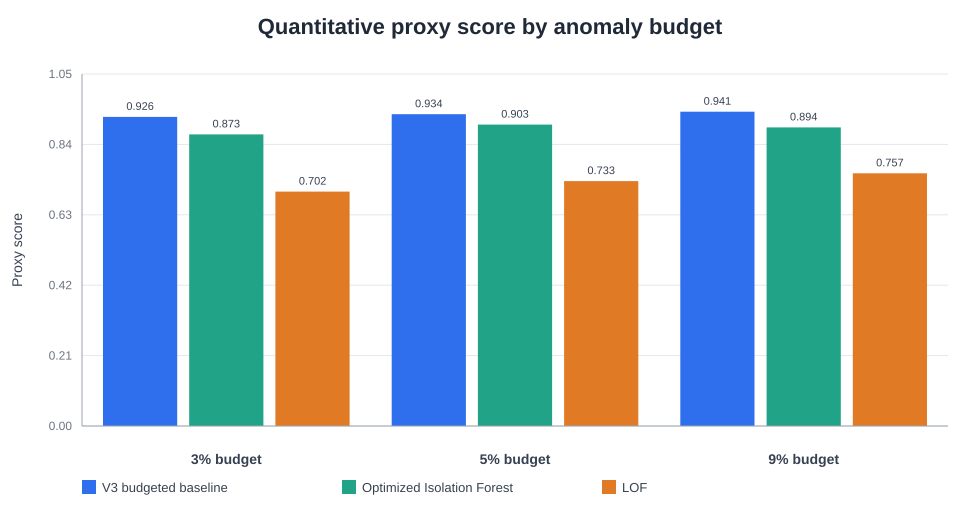

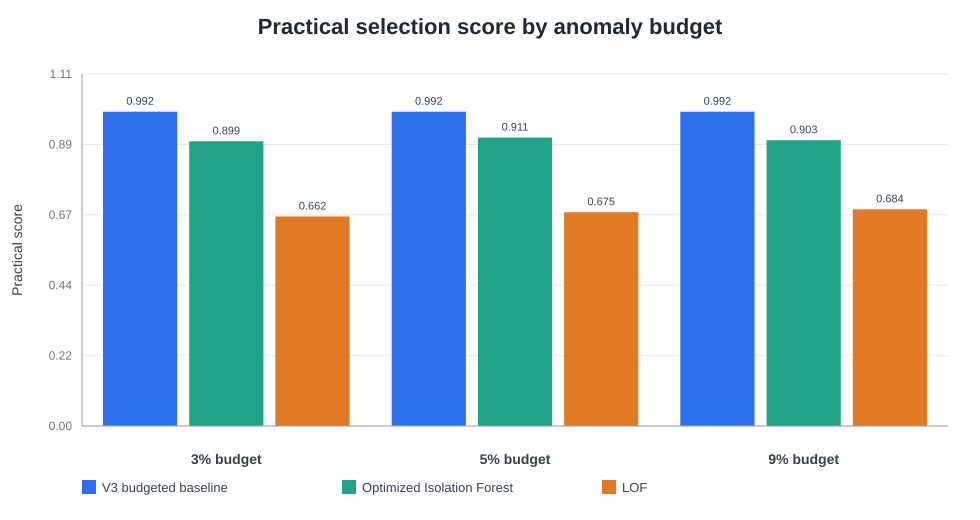

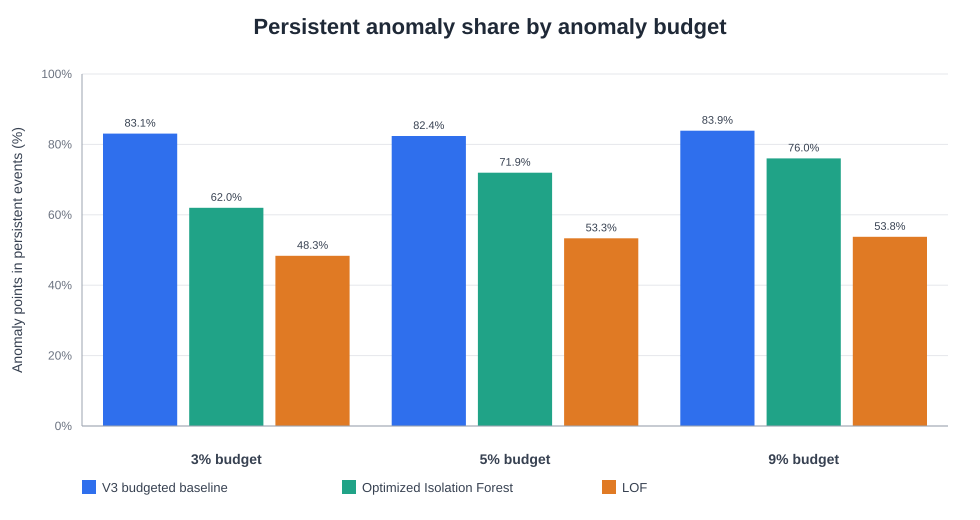

,chart,path,use
0,Quantitative proxy score,outputs\floor6_zone1245_model_method_evaluatio...,Compare methods under fair budget-controlled p...
1,Practical selection score,outputs\floor6_zone1245_model_method_evaluatio...,Support the final project-model decision with ...
2,Persistent anomaly share,outputs\floor6_zone1245_model_method_evaluatio...,Show whether point anomalies form sustained op...


In [8]:
# Generate dependency-free SVG charts for report use.
from html import escape
from IPython.display import SVG

CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

METHOD_COLORS = {
    "V3 budgeted baseline": "#2f6fed",
    "Optimized Isolation Forest": "#20a387",
    "LOF": "#e07a24",
}


def _fmt(value: float, digits: int = 3) -> str:
    return f"{value:.{digits}f}"


def make_grouped_bar_svg(
    data: pd.DataFrame,
    *,
    value_col: str,
    title: str,
    y_label: str,
    output_path: Path,
    value_digits: int = 3,
    percent_axis: bool = False,
) -> Path:
    budgets = sorted(data["budget_pct"].unique())
    methods = ["V3 budgeted baseline", "Optimized Isolation Forest", "LOF"]
    width = 980
    height = 520
    margin = {"left": 82, "right": 32, "top": 74, "bottom": 94}
    plot_w = width - margin["left"] - margin["right"]
    plot_h = height - margin["top"] - margin["bottom"]
    max_value = float(data[value_col].max())
    y_max = max_value * 1.12 if max_value > 0 else 1
    if percent_axis:
        y_max = max(y_max, 100)
    group_w = plot_w / len(budgets)
    bar_gap = 12
    inner_w = group_w - 42
    bar_w = max(18, (inner_w - bar_gap * (len(methods) - 1)) / len(methods))

    def x_pos(budget_index: int, method_index: int) -> float:
        start = margin["left"] + budget_index * group_w + (group_w - inner_w) / 2
        return start + method_index * (bar_w + bar_gap)

    def y_pos(value: float) -> float:
        return margin["top"] + plot_h - (value / y_max) * plot_h

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{escape(title)}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{width/2}" y="34" text-anchor="middle" font-family="Arial" font-size="22" font-weight="700" fill="#1f2937">{escape(title)}</text>',
        f'<text x="22" y="{margin["top"] + plot_h/2}" transform="rotate(-90 22 {margin["top"] + plot_h/2})" text-anchor="middle" font-family="Arial" font-size="14" fill="#374151">{escape(y_label)}</text>',
    ]

    for step in range(6):
        value = y_max * step / 5
        y = y_pos(value)
        label = f"{value:.0f}%" if percent_axis else f"{value:.2f}"
        parts.append(f'<line x1="{margin["left"]}" x2="{width-margin["right"]}" y1="{y:.1f}" y2="{y:.1f}" stroke="#e5e7eb" stroke-width="1"/>')
        parts.append(f'<text x="{margin["left"]-10}" y="{y+4:.1f}" text-anchor="end" font-family="Arial" font-size="12" fill="#6b7280">{label}</text>')

    for b_i, budget in enumerate(budgets):
        subset = data.loc[data["budget_pct"].eq(budget)]
        for m_i, method in enumerate(methods):
            row = subset.loc[subset["method_name"].eq(method)]
            if row.empty:
                continue
            value = float(row[value_col].iloc[0])
            x = x_pos(b_i, m_i)
            y = y_pos(value)
            h = margin["top"] + plot_h - y
            color = METHOD_COLORS[method]
            label = f"{value:.1f}%" if percent_axis else _fmt(value, value_digits)
            parts.append(f'<rect x="{x:.1f}" y="{y:.1f}" width="{bar_w:.1f}" height="{h:.1f}" fill="{color}"/>')
            parts.append(f'<text x="{x + bar_w/2:.1f}" y="{max(58, y-7):.1f}" text-anchor="middle" font-family="Arial" font-size="11" fill="#374151">{label}</text>')
        cx = margin["left"] + b_i * group_w + group_w / 2
        parts.append(f'<text x="{cx:.1f}" y="{height-56}" text-anchor="middle" font-family="Arial" font-size="14" font-weight="700" fill="#374151">{budget:.0f}% budget</text>')

    legend_x = margin["left"]
    legend_y = height - 28
    for i, method in enumerate(methods):
        x = legend_x + i * 260
        parts.append(f'<rect x="{x}" y="{legend_y-12}" width="14" height="14" fill="{METHOD_COLORS[method]}"/>')
        parts.append(f'<text x="{x+20}" y="{legend_y}" font-family="Arial" font-size="13" fill="#374151">{escape(method)}</text>')

    parts.append(f'<line x1="{margin["left"]}" x2="{width-margin["right"]}" y1="{margin["top"]+plot_h}" y2="{margin["top"]+plot_h}" stroke="#9ca3af"/>')
    parts.append(f'<line x1="{margin["left"]}" x2="{margin["left"]}" y1="{margin["top"]}" y2="{margin["top"]+plot_h}" stroke="#9ca3af"/>')
    parts.append('</svg>')
    output_path.write_text("\n".join(parts), encoding="utf-8")
    return output_path


quantitative_chart_data = quantitative_ranking.copy()
quantitative_chart = make_grouped_bar_svg(
    quantitative_chart_data,
    value_col="quantitative_proxy_score",
    title="Quantitative proxy score by anomaly budget",
    y_label="Proxy score",
    output_path=CHART_DIR / "01_quantitative_proxy_score.svg",
)

practical_chart_data = practical_ranking.copy()
practical_chart = make_grouped_bar_svg(
    practical_chart_data,
    value_col="practical_selection_score",
    title="Practical selection score by anomaly budget",
    y_label="Practical score",
    output_path=CHART_DIR / "02_practical_selection_score.svg",
)

persistence_chart_data = quantitative_ranking.copy()
persistence_chart_data["persistent_point_share_pct"] = 100 * persistence_chart_data["persistent_point_share"]
persistence_chart = make_grouped_bar_svg(
    persistence_chart_data,
    value_col="persistent_point_share_pct",
    title="Persistent anomaly share by anomaly budget",
    y_label="Anomaly points in persistent events (%)",
    output_path=CHART_DIR / "03_persistent_event_share.svg",
    value_digits=1,
    percent_axis=True,
)

chart_index = pd.DataFrame([
    {
        "chart": "Quantitative proxy score",
        "path": str(quantitative_chart.relative_to(PROJECT_DIR)),
        "use": "Compare methods under fair budget-controlled proxy metrics.",
    },
    {
        "chart": "Practical selection score",
        "path": str(practical_chart.relative_to(PROJECT_DIR)),
        "use": "Support the final project-model decision with interpretability and output readiness included.",
    },
    {
        "chart": "Persistent anomaly share",
        "path": str(persistence_chart.relative_to(PROJECT_DIR)),
        "use": "Show whether point anomalies form sustained operational events.",
    },
])
chart_index.to_csv(OUTPUT_DIR / "08_chart_index.csv", index=False)

display(Markdown("## Model Comparison Charts"))
display(SVG(filename=str(quantitative_chart)))
display(SVG(filename=str(practical_chart)))
display(SVG(filename=str(persistence_chart)))
display(chart_index)


In [9]:
overall_practical_best = stability.sort_values(["mean_practical_rank", "mean_practical_score"], ascending=[True, False]).iloc[0].to_dict()
overall_quant_best = stability.sort_values(["mean_quantitative_rank", "mean_quantitative_score"], ascending=[True, False]).iloc[0].to_dict()
ml_best = (
    stability.loc[stability["method_key"].isin(["lof", "optimized_if"])]
    .sort_values(["mean_practical_rank", "mean_practical_score"], ascending=[True, False])
    .iloc[0]
    .to_dict()
)

recommendation = {
    "overall_practical_selected_method": overall_practical_best["method_name"],
    "overall_practical_selected_key": overall_practical_best["method_key"],
    "overall_practical_mean_rank": float(overall_practical_best["mean_practical_rank"]),
    "overall_quantitative_proxy_selected_method": overall_quant_best["method_name"],
    "overall_quantitative_proxy_selected_key": overall_quant_best["method_key"],
    "overall_quantitative_proxy_mean_rank": float(overall_quant_best["mean_quantitative_rank"]),
    "primary_unsupervised_ml_method": ml_best["method_name"],
    "primary_unsupervised_ml_key": ml_best["method_key"],
    "primary_unsupervised_ml_mean_practical_rank": float(ml_best["mean_practical_rank"]),
    "budgets_tested_pct": [100 * budget for budget in BUDGETS],
    "quantitative_weights": QUANTITATIVE_WEIGHTS,
    "practical_weights": PRACTICAL_WEIGHTS,
    "selection_basis": (
        "Budget-controlled proxy evaluation using 3%, 5%, and 9% anomaly budgets. "
        "V3 full-baseline overlap is reported as a reference-only diagnostic and is not scored in the quantitative proxy ranking. "
        "No human-confirmed fault label is available, so this is not an accuracy/F1 evaluation."
    ),
    "recommended_use": (
        "Use the selected unsupervised ML method for candidate detection. "
        "Use the V3 baseline as the main explanatory and diagnostic reference, especially for variable-level causes and operating-state context."
    ),
}
(OUTPUT_DIR / "method_selection_summary_optimized.json").write_text(
    json.dumps(recommendation, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

display(Markdown(
    f"""
## Selection Summary

**Overall practical selection:** {recommendation['overall_practical_selected_method']}

**Best quantitative proxy method:** {recommendation['overall_quantitative_proxy_selected_method']}

**Recommended primary unsupervised ML detector:** {recommendation['primary_unsupervised_ml_method']}

The comparison was repeated at **3%, 5%, and 9%**. The V3 full baseline remains an explanatory reference, not a ground-truth label.
"""
))
display(pd.DataFrame([recommendation]).T.rename(columns={0: "value"}))



## Selection Summary

**Overall practical selection:** V3 budgeted baseline

**Best quantitative proxy method:** V3 budgeted baseline

**Recommended primary unsupervised ML detector:** Optimized Isolation Forest

The comparison was repeated at **3%, 5%, and 9%**. The V3 full baseline remains an explanatory reference, not a ground-truth label.


,value
overall_practical_selected_method,V3 budgeted baseline
overall_practical_selected_key,v3_budgeted
overall_practical_mean_rank,1.0
overall_quantitative_proxy_selected_method,V3 budgeted baseline
overall_quantitative_proxy_selected_key,v3_budgeted
overall_quantitative_proxy_mean_rank,1.0
primary_unsupervised_ml_method,Optimized Isolation Forest
primary_unsupervised_ml_key,optimized_if
primary_unsupervised_ml_mean_practical_rank,2.0
budgets_tested_pct,"[3.0, 5.0, 9.0]"


In [10]:
# Generate a report-ready conclusion and final model decision directly from the computed rankings.
quantitative = pd.read_csv(OUTPUT_DIR / "04_quantitative_proxy_ranking.csv")
practical = pd.read_csv(OUTPUT_DIR / "05_practical_selection_ranking.csv")
stability_final = pd.read_csv(OUTPUT_DIR / "06_budget_stability_summary.csv")
recommendation_final = json.loads((OUTPUT_DIR / "method_selection_summary_optimized.json").read_text(encoding="utf-8"))

v3_stability = stability_final.loc[stability_final["method_key"].eq("v3_budgeted")].iloc[0]
if_stability = stability_final.loc[stability_final["method_key"].eq("optimized_if")].iloc[0]
lof_stability = stability_final.loc[stability_final["method_key"].eq("lof")].iloc[0]

quant_table = quantitative[[
    "budget_pct",
    "quantitative_rank",
    "method_name",
    "quantitative_proxy_score",
    "common_event_count",
    "persistent_point_share",
]].copy()
quant_table["persistent_point_share_pct"] = 100 * quant_table["persistent_point_share"]

conclusion_text = f"""
## Report Conclusion and Final Model Choice

For the overall project, the recommended final model is the **V3 operation-aware statistical baseline**. It should be used as the main model for the later analysis, interpretation, event explanation, and report narrative.

This choice is supported by the budget-controlled proxy evaluation. The **V3 budgeted baseline** ranks first at all tested anomaly budgets (**3%, 5%, and 9%**) in both the quantitative proxy ranking and the practical selection ranking. Its mean quantitative rank is **{v3_stability['mean_quantitative_rank']:.1f}**, and its mean practical rank is **{v3_stability['mean_practical_rank']:.1f}**.

Among the two unsupervised machine-learning methods, **Optimized Isolation Forest** is the better detector. It ranks second at all three budgets, ahead of LOF, with a mean quantitative rank of **{if_stability['mean_quantitative_rank']:.1f}** and a mean practical rank of **{if_stability['mean_practical_rank']:.1f}**. LOF ranks third across the tested budgets, with a mean quantitative rank of **{lof_stability['mean_quantitative_rank']:.1f}**.

The recommended modelling strategy is therefore:

1. Use **V3 operation-aware statistical baseline** as the project's final/main model.
2. Use **Optimized Isolation Forest** as a supporting unsupervised ML benchmark or secondary candidate detector.
3. Do not choose **LOF** as the main project model, because it is less stable and less useful for event-level interpretation in this comparison.

This conclusion is based on equal anomaly-budget comparisons at **3%, 5%, and 9%**. The V3 full-baseline overlap is reported only as a reference diagnostic and is not used as a scored criterion in the quantitative proxy ranking, which avoids giving the V3 method an unfair advantage against IF and LOF.

Because there is no human-confirmed ground-truth fault label, this is a **proxy model-selection evaluation**, not an accuracy, precision, recall, or F1-score evaluation.
""".strip()

(OUTPUT_DIR / "07_report_ready_conclusion.md").write_text(conclusion_text + "\n", encoding="utf-8")

display(Markdown(conclusion_text))
display(quant_table)


## Report Conclusion and Final Model Choice

For the overall project, the recommended final model is the **V3 operation-aware statistical baseline**. It should be used as the main model for the later analysis, interpretation, event explanation, and report narrative.

This choice is supported by the budget-controlled proxy evaluation. The **V3 budgeted baseline** ranks first at all tested anomaly budgets (**3%, 5%, and 9%**) in both the quantitative proxy ranking and the practical selection ranking. Its mean quantitative rank is **1.0**, and its mean practical rank is **1.0**.

Among the two unsupervised machine-learning methods, **Optimized Isolation Forest** is the better detector. It ranks second at all three budgets, ahead of LOF, with a mean quantitative rank of **2.0** and a mean practical rank of **2.0**. LOF ranks third across the tested budgets, with a mean quantitative rank of **3.0**.

The recommended modelling strategy is therefore:

1. Use **V3 operation-aware statistical baseline** as the project's final/main model.
2. Use **Optimized Isolation Forest** as a supporting unsupervised ML benchmark or secondary candidate detector.
3. Do not choose **LOF** as the main project model, because it is less stable and less useful for event-level interpretation in this comparison.

This conclusion is based on equal anomaly-budget comparisons at **3%, 5%, and 9%**. The V3 full-baseline overlap is reported only as a reference diagnostic and is not used as a scored criterion in the quantitative proxy ranking, which avoids giving the V3 method an unfair advantage against IF and LOF.

Because there is no human-confirmed ground-truth fault label, this is a **proxy model-selection evaluation**, not an accuracy, precision, recall, or F1-score evaluation.

,budget_pct,quantitative_rank,method_name,quantitative_proxy_score,common_event_count,persistent_point_share,persistent_point_share_pct
0,3.0,1,V3 budgeted baseline,0.925805,66,0.830624,83.062368
1,3.0,2,Optimized Isolation Forest,0.873412,77,0.620006,62.000551
2,3.0,3,LOF,0.702138,73,0.483465,48.346500
3,5.0,1,V3 budgeted baseline,0.933983,118,0.823743,82.374339
4,5.0,2,Optimized Isolation Forest,0.902708,134,0.719466,71.946649
5,5.0,3,LOF,0.733445,138,0.533289,53.328924
6,9.0,1,V3 budgeted baseline,0.941422,204,0.838885,83.888549
7,9.0,2,Optimized Isolation Forest,0.894423,247,0.760318,76.031843
8,9.0,3,LOF,0.756870,225,0.537555,53.755473


In [11]:
print("Generated optimized evaluation outputs:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(path.relative_to(PROJECT_DIR))


Generated optimized evaluation outputs:
outputs\floor6_zone1245_model_method_evaluation_optimized\01_budgeted_point_metrics.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\02_budgeted_common_rule_events.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\03_pairwise_overlap_by_budget.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\04_quantitative_proxy_ranking.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\05_practical_selection_ranking.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\06_budget_stability_summary.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\07_report_ready_conclusion.md
outputs\floor6_zone1245_model_method_evaluation_optimized\08_chart_index.csv
outputs\floor6_zone1245_model_method_evaluation_optimized\charts
outputs\floor6_zone1245_model_method_evaluation_optimized\method_selection_summary_optimized.json
